### Low Fidelity NN

Investigate regression fit for a non-linear function as a starting point for multi-fidelity model fitting. 


In [1]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)

C:\Users\troyz\GitProjects\SurrogateModeling\SurrogateModels


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, mfsnn
import torch
import torch.nn

# Set the random seed
torch.manual_seed(17)
DEVICE='cpu'
DTYPE=torch.float32

Add the low fidelity function as a data source for the model and sample it. For an initial test this uses 30 samples and 300 for the full function definition.

In [3]:
fxn_ind = 1
n_samp = 30
n_check = 300
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)

X_lf = np.zeros([n_samp,1])
X_lf[:,0] = np.linspace(0.0,1.0,n_samp,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = torch.tensor(X_lf, dtype=torch.float32)
y_lf = torch.tensor(y_lf, dtype=torch.float32)

X_check = np.zeros([n_check,1])
X_check[:,0] = np.linspace(0,1.0,n_check,endpoint=True)
y_check = lf_fxn.evaluate(X_check)
X_check = torch.tensor(X_check, dtype=torch.float32)
y_check = torch.tensor(y_check, dtype=torch.float32)

Define a loss function and set up the model. The initial model will have 3 hidden layers with 10 nodes and will utilize a tanh activation function that was defined in the paper "A Composite neural network that learns from multi-fidelity data: Application to funciton approximation and inverse PDE problems" Meng & Kamiadkis 2020

This neural network approach utilizes the Adam optimizer. This was the issue with the network discussed in the Q&A. It turns out the learning rate was set too small. A larger learning rate allowed the error to converge for the network.

Initialization of the model also trains the network.

In [4]:
loss = torch.nn.MSELoss()
lf_model = mfsnn.LowFidelityNN(X_lf,y_lf,X_check,y_check,[10,10,10], torch.nn.Tanh(),loss)

----Progress Update----
Epoch: 0 

Training Error: 1.127532720565796 

Validation Error: 0.14388622343540192 

----Progress Update----
Epoch: 50 

Training Error: 0.2862384617328644 

Validation Error: 0.17454367876052856 

----Progress Update----
Epoch: 100 

Training Error: 0.006801429204642773 

Validation Error: 1.1706462828442454e-05 

----Progress Update----
Epoch: 150 

Training Error: 0.0056750718504190445 

Validation Error: 3.302007098682225e-05 

----Progress Update----
Epoch: 200 

Training Error: 0.005383358336985111 

Validation Error: 2.2752685254090466e-05 

----Progress Update----
Epoch: 250 

Training Error: 0.005204460117965937 

Validation Error: 1.1687344340316486e-05 

----Progress Update----
Epoch: 300 

Training Error: 0.005071302875876427 

Validation Error: 6.799056791351177e-06 

----Progress Update----
Epoch: 350 

Training Error: 0.004951667506247759 

Validation Error: 5.461374257720308e-06 

----Progress Update----
Epoch: 400 

Training Error: 0.004584661

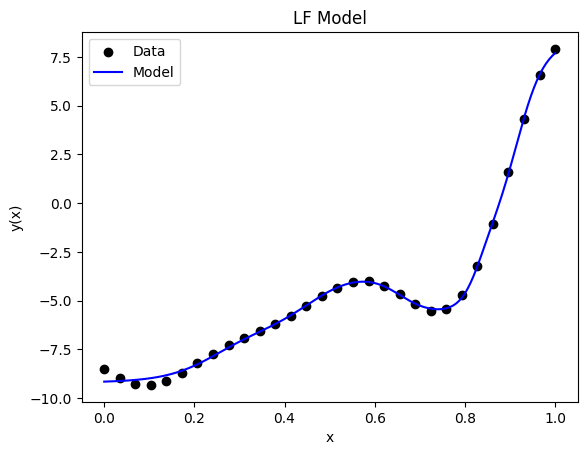

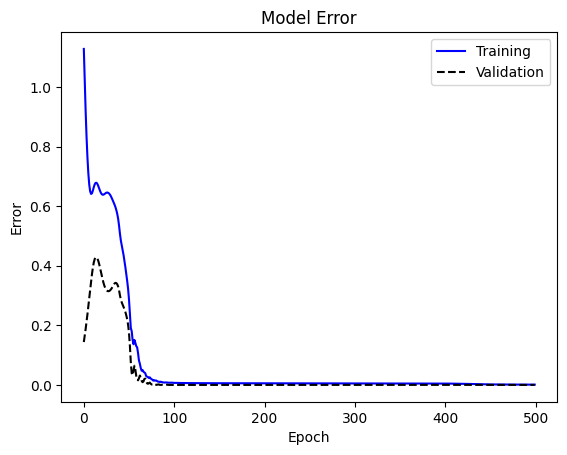

In [5]:
# Plot the results
lf_model.plot_data("LF Model", label = "Data")
lf_model.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model.plot_error()

## Experiments on Model Depth

Test the number of layers of size 10 effect on model accuracy with the same number of epochs.

----Progress Update----
Epoch: 0 

Training Error: 1.2634626626968384 

Validation Error: 0.12173337489366531 

----Progress Update----
Epoch: 50 

Training Error: 0.17876845598220825 

Validation Error: 0.064960777759552 

----Progress Update----
Epoch: 100 

Training Error: 0.1476285606622696 

Validation Error: 0.05876082554459572 

----Progress Update----
Epoch: 150 

Training Error: 0.1276862472295761 

Validation Error: 0.04522345960140228 

----Progress Update----
Epoch: 200 

Training Error: 0.1083746999502182 

Validation Error: 0.03161840885877609 

----Progress Update----
Epoch: 250 

Training Error: 0.08917572349309921 

Validation Error: 0.02028266154229641 

----Progress Update----
Epoch: 300 

Training Error: 0.06701258569955826 

Validation Error: 0.011748352088034153 

----Progress Update----
Epoch: 350 

Training Error: 0.04409646615386009 

Validation Error: 0.005374203901737928 

----Progress Update----
Epoch: 400 

Training Error: 0.029932742938399315 

Validation 

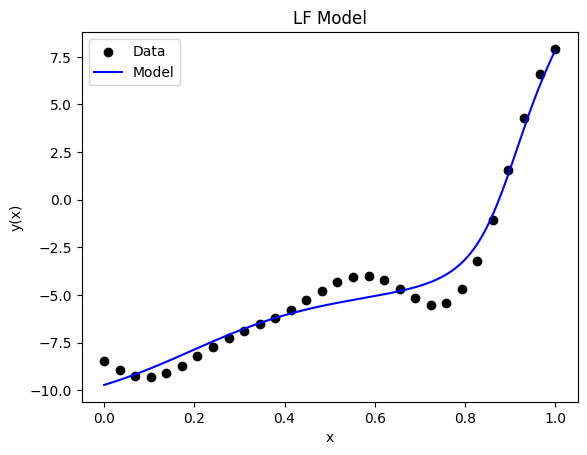

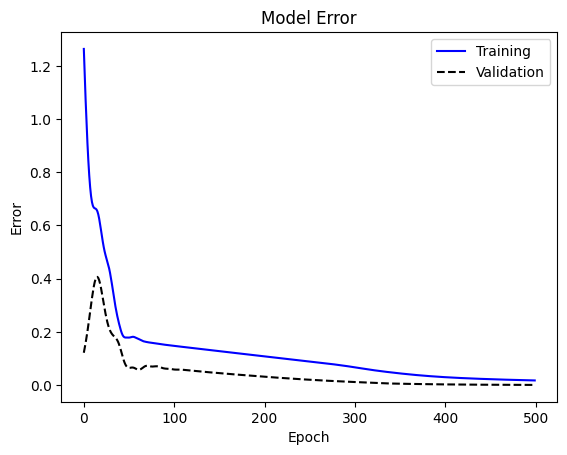

In [6]:
# Start with a single model layer of size 10
lf_model_1 = mfsnn.LowFidelityNN(X_lf,y_lf,X_check,y_check,[10], torch.nn.Tanh(),loss)
lf_model_1.plot_data("LF Model", label = "Data")
lf_model_1.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model_1.plot_error()

----Progress Update----
Epoch: 0 

Training Error: 1.3471848964691162 

Validation Error: 0.11586230248212814 

----Progress Update----
Epoch: 50 

Training Error: 0.18107181787490845 

Validation Error: 0.07099354267120361 

----Progress Update----
Epoch: 100 

Training Error: 0.13503463566303253 

Validation Error: 0.0549573078751564 

----Progress Update----
Epoch: 150 

Training Error: 0.10229134559631348 

Validation Error: 0.030915390700101852 

----Progress Update----
Epoch: 200 

Training Error: 0.07841254025697708 

Validation Error: 0.01803532987833023 

----Progress Update----
Epoch: 250 

Training Error: 0.05854681879281998 

Validation Error: 0.010703840292990208 

----Progress Update----
Epoch: 300 

Training Error: 0.04439928010106087 

Validation Error: 0.006085659842938185 

----Progress Update----
Epoch: 350 

Training Error: 0.035633645951747894 

Validation Error: 0.0036912246141582727 

----Progress Update----
Epoch: 400 

Training Error: 0.030097125098109245 

Val

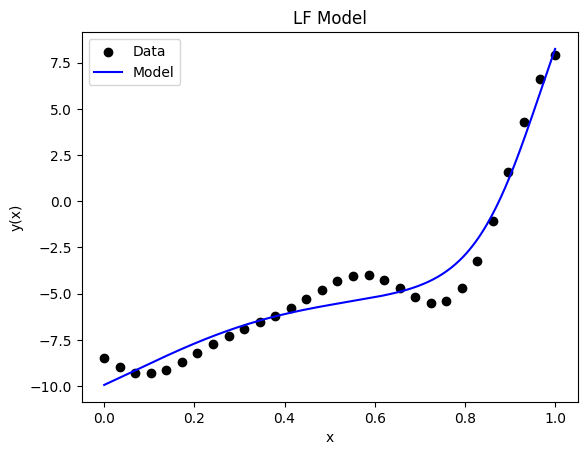

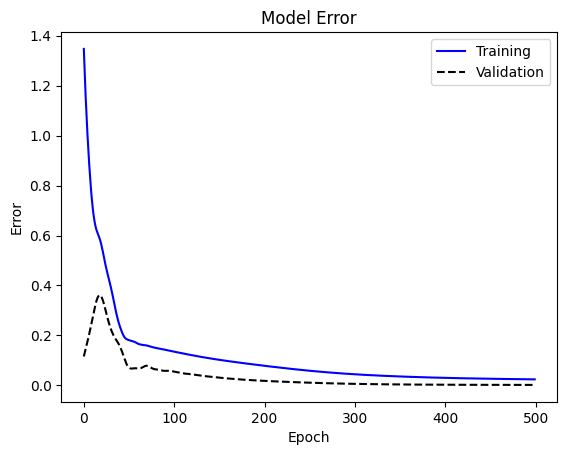

In [7]:
# Model with 2 layers
lf_model_2 = mfsnn.LowFidelityNN(X_lf,y_lf,X_check,y_check,[10,10], torch.nn.Tanh(),loss)
lf_model_2.plot_data("LF Model", label = "Data")
lf_model_2.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model_2.plot_error()

----Progress Update----
Epoch: 0 

Training Error: 1.2713006734848022 

Validation Error: 0.12037155032157898 

----Progress Update----
Epoch: 50 

Training Error: 0.6399996876716614 

Validation Error: 0.3414439558982849 

----Progress Update----
Epoch: 100 

Training Error: 0.6392923593521118 

Validation Error: 0.35082635283470154 

----Progress Update----
Epoch: 150 

Training Error: 0.6392913460731506 

Validation Error: 0.3511529862880707 

----Progress Update----
Epoch: 200 

Training Error: 0.6392912268638611 

Validation Error: 0.35119396448135376 

----Progress Update----
Epoch: 250 

Training Error: 0.6392911672592163 

Validation Error: 0.3511934280395508 

----Progress Update----
Epoch: 300 

Training Error: 0.6392910480499268 

Validation Error: 0.35119369626045227 

----Progress Update----
Epoch: 350 

Training Error: 0.6392909288406372 

Validation Error: 0.35119369626045227 

----Progress Update----
Epoch: 400 

Training Error: 0.6392908096313477 

Validation Error: 0.

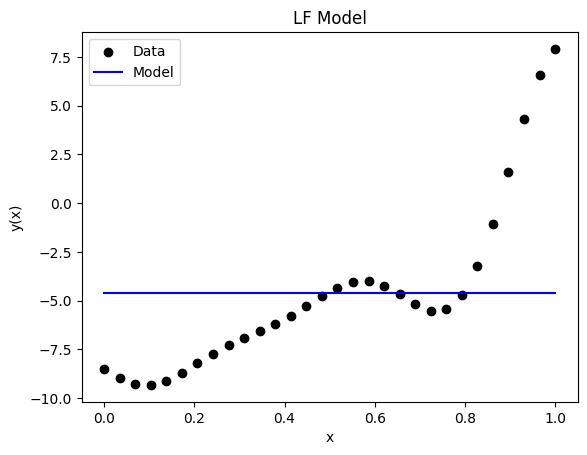

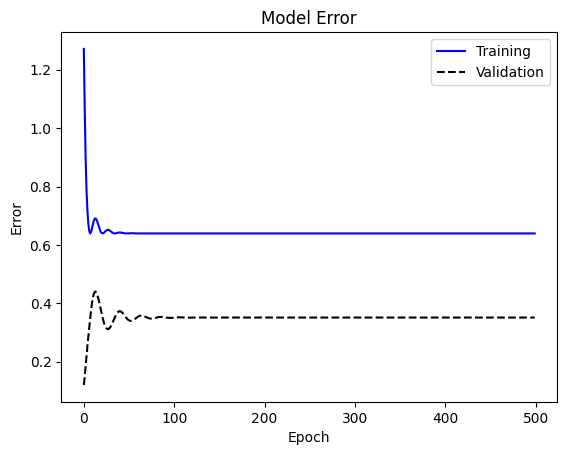

In [8]:
# Model with 4 layers
lf_model_4 = mfsnn.LowFidelityNN(X_lf,y_lf,X_check,y_check,[10,10,10,10], torch.nn.Tanh(),loss)
lf_model_4.plot_data("LF Model", label = "Data")
lf_model_4.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model_4.plot_error()

It seems that the issues with the learning rate need to be tuned individually for each network size. This was an unexpected development of model tuning.